## 1. Import packages and set folders

All premiums below are in USD millions.

In [ ]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap
from IPython.display import display
from statsmodels.tsa.statespace.structural import UnobservedComponents
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import kpss

# Locate the repository from the current folder (repository root or code/).
working_folder = Path.cwd().resolve()
project_folder = next(
    (folder for folder in (working_folder, *working_folder.parents)
     if all((folder / name).is_dir() for name in ("code", "dataset_raw", "dataset_analysis"))),
    None,
)
if project_folder is None:
    raise FileNotFoundError(
        "Open Jupyter from the repository root or its code folder. "
        "Expected code/, dataset_raw/, and dataset_analysis/."
    )
output_folder = project_folder / "output"
data_folder = project_folder / "dataset_analysis"

save_figures = False


analysis_years = np.arange(1995, 2025)

minimum_observations = 12
minimum_validation_blocks = 3
maximum_validation_blocks = 6

show_all_country_pages = True
countries_per_page = 6

## 2. Load the selected countries and earlier history

Blank values are missing. Reported zeros and negatives remain numbers.

In [26]:
selected_file = data_folder / "02_selected_insurance_rows.csv"
history_file = data_folder / "01_scoped_insurance_history.csv"

if not selected_file.exists() or not history_file.exists():
    raise FileNotFoundError("Run notebooks 01 and 02 first.")

selected_rows = pd.read_csv(selected_file, dtype=str, keep_default_na=False)
history_rows = pd.read_csv(history_file, dtype=str, keep_default_na=False)

original_columns = selected_rows.columns.tolist()
country_names = selected_rows[["REF_AREA", "Reference area"]].drop_duplicates()
country_names = country_names.sort_values("Reference area").reset_index(drop=True)
country_order = country_names["Reference area"].tolist()

insurance_types = ["Life", "Composite: life", "Non-life", "Composite: non-life"]
business_types = ["Direct business", "Reinsurance accepted"]

history_rows = history_rows.loc[
    history_rows["REF_AREA"].isin(country_names["REF_AREA"])
    & history_rows["Insurance type"].isin(insurance_types)
    & history_rows["Insurance business"].isin(business_types)
].copy()
history_rows["Year"] = history_rows["TIME_PERIOD"].astype(int)
premium_text = history_rows["OBS_VALUE"].str.strip().str.lstrip("'")
history_rows["Premium"] = pd.to_numeric(premium_text.mask(premium_text.eq("")), errors="raise")
assert history_rows["UNIT_MULT"].eq("6").all()
history_years = np.arange(history_rows["Year"].min(), analysis_years.max() + 1)

assert not history_rows.duplicated(["REF_AREA", "Year", "Insurance type", "Insurance business"]).any()
print("Selected countries:", len(country_names))
print("History:", history_years.min(), "to", history_years.max())

display(country_names)
display(history_rows[["Reference area", "Year", "Insurance type", "Insurance business", "Premium"]].head(10))

Selected countries: 30
History: 1983 to 2024


,REF_AREA,Reference area
0,AUS,Australia
1,AUT,Austria
2,BEL,Belgium
3,CAN,Canada
4,CZE,Czechia
5,DNK,Denmark
6,FIN,Finland
7,FRA,France
8,DEU,Germany
9,GRC,Greece


,Reference area,Year,Insurance type,Insurance business,Premium
0,Australia,2012,Composite: non-life,Reinsurance accepted,NaN
1,Australia,2013,Composite: non-life,Reinsurance accepted,NaN
2,Australia,2014,Composite: non-life,Reinsurance accepted,NaN
3,Australia,2015,Composite: non-life,Reinsurance accepted,NaN
4,Sweden,2015,Composite: non-life,Reinsurance accepted,NaN
5,Sweden,2016,Composite: non-life,Reinsurance accepted,NaN
6,Sweden,2017,Composite: non-life,Reinsurance accepted,NaN
7,Sweden,2018,Composite: non-life,Reinsurance accepted,NaN
8,Sweden,2019,Composite: non-life,Reinsurance accepted,NaN
9,Sweden,2021,Composite: non-life,Reinsurance accepted,NaN


## 3. Find consecutive gaps

In [27]:
def find_missing_gaps(values):
    missing_positions = np.flatnonzero(np.isnan(values))
    if len(missing_positions) == 0:
        return []
    new_gap_starts = np.flatnonzero(np.diff(missing_positions) > 1) + 1
    return np.split(missing_positions, new_gap_starts)


def get_gap_type(gap_positions, number_of_years):
    if gap_positions[0] == 0:
        return "leading"
    if gap_positions[-1] == number_of_years - 1:
        return "trailing"
    return "internal"


example_values = np.array([np.nan, np.nan, 100, 120, np.nan, 160, np.nan])
for example_gap in find_missing_gaps(example_values):
    print(example_gap, get_gap_type(example_gap, len(example_values)))

[0 1] leading
[4] internal
[6] trailing


## 4. Internal gaps: linear interpolation and Kalman smoothing

Linear interpolation joins observed values with a straight line. Kalman smoothing uses a changing level and trend, with observations before and after the gap. Scaling improves numerical stability. Predictions return to the original scale.

In [28]:
def predict_linear(values, gap_positions):
    observed_positions = np.flatnonzero(np.isfinite(values))
    return np.interp(gap_positions, observed_positions, values[observed_positions])


def predict_kalman(values, gap_positions):
    center = np.nanmean(values)
    scale = np.nanstd(values)
    if scale < 1e-12:
        return np.repeat(center, len(gap_positions))
    scaled_values = (values - center) / scale
    model = UnobservedComponents(scaled_values, level="local linear trend")
    fitted_model = model.fit(disp=False, maxiter=200)
    if not fitted_model.mle_retvals.get("converged", False):
        return None
    return center + scale * fitted_model.smoothed_state[0, gap_positions]

## 5. Edge gaps: Naive, ETS and ARIMA

Use the continuous observed block next to a gap. Reverse history for leading gaps.

- Naive repeats the nearest value.
- ETS compares additive-error, nonseasonal models: no trend, additive trend, damped trend.
- ARIMA uses KPSS to choose 0 or 1 difference, then compares small nonseasonal models with `p` and `q` from 0 to 1. 

AICc chooses a model **within** ETS or ARIMA. Held-out RMSE later compares methods.

In [29]:
def get_adjacent_history(values, gap_positions, gap_type):
    if gap_type == "leading":
        nearest_first = values[gap_positions[-1] + 1:]
    else:
        nearest_first = values[:gap_positions[0]][::-1]
    missing_positions = np.flatnonzero(np.isnan(nearest_first))

    if len(missing_positions):
        nearest_first = nearest_first[:missing_positions[0]]
    if len(nearest_first) < minimum_observations:
        return None
    return nearest_first[::-1]


def predict_ets(training_values, horizon):
    best_aicc = np.inf
    best_prediction = None
    for trend, damped in [(None, False), ("add", False), ("add", True)]:
        try:
            model = ETSModel(training_values, error="add", trend=trend,
                             damped_trend=damped, seasonal=None)
            fitted_model = model.fit(disp=False, maxiter=300)
            if not fitted_model.mle_retvals.get("converged", False):
                continue
            if np.isfinite(fitted_model.aicc) and fitted_model.aicc < best_aicc:
                best_aicc = fitted_model.aicc
                best_prediction = np.asarray(fitted_model.forecast(horizon))
        except (ValueError, np.linalg.LinAlgError):
            continue
    
    if best_prediction is None:
        raise ValueError("No valid ETS model.")
    
    return best_prediction


def predict_arima(training_values, horizon):
    kpss_pvalue = kpss(training_values, regression="c", nlags="auto")[1]
    differences = int(kpss_pvalue < 0.05)
    trend_options = ["n", "c"] if differences == 0 else ["n", "t"]
    best_aicc = np.inf
    best_prediction = None
    
    for ar_order in [0, 1]:
        for ma_order in [0, 1]:
            for trend in trend_options:
                try:
                    model = ARIMA(training_values, order=(ar_order, differences, ma_order), trend=trend)
                    fitted_model = model.fit(method_kwargs={"maxiter": 150})
                    if not fitted_model.mle_retvals.get("converged", False):
                        continue
                    if np.isfinite(fitted_model.aicc) and fitted_model.aicc < best_aicc:
                        best_aicc = fitted_model.aicc
                        best_prediction = np.asarray(fitted_model.forecast(horizon))
                except (ValueError, np.linalg.LinAlgError):
                    continue
    
    if best_prediction is None:
        raise ValueError("No valid ARIMA model.")
    
    return best_prediction

## 6. Run one prediction safely

`_level` means the original scale. `_log` means taking logs before prediction and exponentiating afterward. Log methods require strictly positive observations. Exponentiation has no mean-bias correction.

Insufficient adjacent history, non-converged Kalman fits, and invalid predictions return no result, so the candidate is excluded. Model warnings appear directly. Unexpected model errors can still stop execution. No prediction cache is used.

In [30]:
def predict_gap(values, gap_positions, method, gap_type):
    model_values = values.copy()
    use_log = method.endswith("_log")

    if use_log:
        if np.any(model_values[np.isfinite(model_values)] <= 0):
            raise ValueError("Log methods require positive observations.")
        model_values = np.log(model_values)

    method_name = method.split("_")[0]
    gap_length = len(gap_positions)

    if method_name == "linear":
        prediction = predict_linear(model_values, gap_positions)
    elif method_name == "kalman":
        prediction = predict_kalman(model_values, gap_positions)
        if prediction is None:
            return None, "Kalman optimization did not converge."
    else:
        training = get_adjacent_history(model_values, gap_positions, gap_type)
        if training is None:
            return None, "Not enough continuous observations next to the gap."
        
        center = training.mean()
        scale = training.std()

        if method_name == "naive" or scale < 1e-12:
            prediction = np.repeat(training[-1], gap_length)
        else:
            scaled_training = (training - center) / scale
            if method_name == "ets":
                prediction = predict_ets(scaled_training, gap_length)
            elif method_name == "arima":
                prediction = predict_arima(scaled_training, gap_length)
            else:
                raise ValueError("Unknown method.")
            prediction = center + scale * prediction

        if gap_type == "leading":
            prediction = prediction[::-1]

    if use_log:
        prediction = np.exp(prediction)

    if len(prediction) != gap_length or not np.isfinite(prediction).all():
        return None, "Invalid prediction."
    if np.all(values[np.isfinite(values)] >= 0) and np.any(prediction < 0):
        return None, "Negative prediction for a nonnegative history."

    return np.asarray(prediction), ""


## 7. Validate with observed blocks

Hide consecutive observed years matching the real gap length and type. Respect reported breaks and require at least 12 usable observations. Leading validation cannot use earlier values and trailing validation cannot use later values.

RMSE is calculated across all held-out predictions in original USD millions.

In [31]:
def find_validation_blocks(values, gap_length, gap_type, reported_breaks):
    blocks = []
    for start in range(len(values) - gap_length + 1):
        positions = np.arange(start, start + gap_length)
        end = positions[-1]
        if np.isnan(values[positions]).any() or reported_breaks[positions].any():
            continue
        if np.isfinite(np.delete(values, positions)).sum() < minimum_observations:
            continue
        if gap_type == "internal":
            if start == 0 or end == len(values) - 1:
                continue
            if np.isnan(values[start - 1]) or np.isnan(values[end + 1]) or reported_breaks[end + 1]:
                continue
        else:
            if gap_type == "leading":
                if end == len(values) - 1 or np.isnan(values[end + 1]) or reported_breaks[end + 1]:
                    continue
            elif start == 0 or np.isnan(values[start - 1]):
                continue
            if get_adjacent_history(values, positions, gap_type) is None:
                continue

        blocks.append(positions)
    return blocks


def evaluate_method(values, gap_positions, validation_blocks, method, gap_type):
    actual_values = []
    predicted_values = []
    messages = []
    for positions in validation_blocks:
        hidden_values = values.copy()
        hidden_values[positions] = np.nan
        if gap_type == "leading":
            hidden_values[:positions[0]] = np.nan
        if gap_type == "trailing":
            hidden_values[positions[-1] + 1:] = np.nan
        prediction, message = predict_gap(hidden_values, positions, method, gap_type)
        if prediction is None:
            return None, np.nan, np.nan, message
        actual_values.extend(values[positions])
        predicted_values.extend(prediction)
        if message:
            messages.append(message)
    errors = np.array(predicted_values) - np.array(actual_values)
    rmse = np.sqrt(np.mean(errors ** 2))
    mae = np.mean(np.abs(errors))
    prediction, message = predict_gap(values, gap_positions, method, gap_type)
    if prediction is None:
        return None, np.nan, np.nan, message
    if message:
        messages.append(message)
    return prediction, rmse, mae, "; ".join(dict.fromkeys(messages))

## 8. Choose a method for one gap

Compare full history with history starting in 1995 where possible, using shared validation blocks. A reported break restricts the usable history. Require at least 3 validation blocks and use at most 6. These are project choices, not guarantees.

In [ ]:
def choose_gap_method(values, gap_positions, gap_type, reported_breaks):
    earlier_breaks = np.flatnonzero(reported_breaks & (np.arange(len(values)) < gap_positions[0]))
    later_breaks = np.flatnonzero(reported_breaks & (np.arange(len(values)) > gap_positions[-1]))
    lower = earlier_breaks[-1] if len(earlier_breaks) else 0
    upper = later_breaks[0] if len(later_breaks) else len(values)
    full_positions = np.arange(lower, upper)
    blocks = find_validation_blocks(values[full_positions], len(gap_positions),
                                    gap_type, reported_breaks[full_positions])
    common_blocks = [full_positions[block] for block in blocks]
    history_options = {"Full history": full_positions}
    if history_years[gap_positions[0]] >= 1995:
        recent_start = max(lower, int(np.searchsorted(history_years, 1995)))
        recent_positions = np.arange(recent_start, upper)
        history_options["1995 onward"] = recent_positions
        common_blocks = [block for block in common_blocks if np.all(history_years[block] >= 1995)]
        blocks = find_validation_blocks(values[recent_positions], len(gap_positions),
                                        gap_type, reported_breaks[recent_positions])
        recent_blocks = {tuple(recent_positions[block]) for block in blocks}
        shared_blocks = [block for block in common_blocks if tuple(block) in recent_blocks]
        if len(shared_blocks) >= minimum_validation_blocks:
            common_blocks = shared_blocks
    if len(common_blocks) > maximum_validation_blocks:
        keep = np.unique(np.round(np.linspace(0, len(common_blocks) - 1,
                                               maximum_validation_blocks)).astype(int))
        common_blocks = [common_blocks[number] for number in keep]

    candidate_rows = []
    predictions = []
    for history_name, history_positions in history_options.items():
        model_values = values[history_positions]
        if np.isfinite(model_values).sum() < minimum_observations:
            continue
        if len(common_blocks) < minimum_validation_blocks:
            continue
        if not all(np.isin(block, history_positions).all() for block in common_blocks):
            continue
        target_positions = gap_positions - history_positions[0]
        validation_blocks = [block - history_positions[0] for block in common_blocks]
        if gap_type == "internal":
            methods = ["linear_level", "kalman_level"]
        else:
            methods = ["naive_level", "ets_level", "arima_level"]
        if np.all(model_values[np.isfinite(model_values)] > 0):
            methods += [method.replace("_level", "_log") for method in methods if not method.startswith("naive")]
        for method in methods:
            prediction, rmse, mae, message = evaluate_method(
                model_values, target_positions, validation_blocks, method, gap_type)
            candidate_rows.append({"History": history_name, "Method": method,
                                   "Blocks": len(validation_blocks), "RMSE": rmse,
                                   "MAE": mae, "Message": message, "Selected": False})
            predictions.append(prediction)

    valid = [number for number, row in enumerate(candidate_rows) if np.isfinite(row["RMSE"])]
    if not valid:
        return None, candidate_rows
    lowest_rmse = min(candidate_rows[number]["RMSE"] for number in valid)
    tolerance = max(1e-6, lowest_rmse * 1e-8)
    tied = [number for number in valid if candidate_rows[number]["RMSE"] <= lowest_rmse + tolerance]
    
    def tie_priority(number):
        row = candidate_rows[number]
        simple = row["Method"].startswith(("linear", "naive"))
        return 10 * int(not simple) + int(row["History"] == "Full history")
    best_number = min(tied, key=tie_priority)
    candidate_rows[best_number]["Selected"] = True
    best_result = candidate_rows[best_number].copy()
    best_result["values"] = predictions[best_number]
    return best_result, candidate_rows

## 9. Apply imputation to all countries

This is the main calculation cell. It may take several minutes and prints each completed country. The four original insurance types are processed separately. Every prediction uses original observations, not earlier imputed values. Unsupported gaps stay missing. 

In [33]:
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning, ConvergenceWarning

warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="Non-stationary starting autoregressive parameters.*")
warnings.filterwarnings("ignore", message="Non-invertible starting MA parameters.*")

series_tables = []
validation_rows = []
gap_rows = []

for country_code, country_name in country_names.itertuples(index=False, name=None):
    for insurance_type in insurance_types:
        for business_type in business_types:
            one_history = history_rows.loc[
                history_rows["REF_AREA"].eq(country_code)
                & history_rows["Insurance type"].eq(insurance_type)
                & history_rows["Insurance business"].eq(business_type)
            ].set_index("Year").reindex(history_years)
            values = one_history["Premium"].to_numpy(dtype=float)
            reported_breaks = one_history["OBS_STATUS"].eq("B").to_numpy()
            result = pd.DataFrame({
                "REF_AREA": country_code, "Country": country_name, "Type": insurance_type,
                "Business": business_type, "Year": history_years, "Observed": values,
                "Filled": values.copy(), "Is_imputed": False, "Method": "Observed",
                "Status": "Observed", "Gap_type": "", "History": "",
                "Blocks": np.nan, "RMSE": np.nan, "MAE": np.nan,
            })
            result.loc[np.isnan(values), "Method"] = ""
            for gap_positions in find_missing_gaps(values):
                gap_type = get_gap_type(gap_positions, len(values))
                gap_label = f"{history_years[gap_positions[0]]}-{history_years[gap_positions[-1]]}"
                result.loc[gap_positions, "Gap_type"] = gap_type
                reason = ""
                
                if np.isfinite(values).sum() == 0:
                    reason = "Unresolved: no observed values; applicability unknown"
                elif np.isfinite(values).sum() < minimum_observations:
                    reason = "Unresolved: too few observations"
                next_position = gap_positions[-1] + 1
                if reported_breaks[gap_positions].any() or (
                    next_position < len(values) and reported_breaks[next_position]
                ):
                    reason = "Unresolved: reported break at gap"
                best_result = None
                
                if not reason:
                    best_result, candidates = choose_gap_method(values, gap_positions, gap_type, reported_breaks)
                    for row in candidates:
                        row.update(Country=country_name, Type=insurance_type, Business=business_type,
                                   Gap=gap_label, Gap_type=gap_type)
                        validation_rows.append(row)
                    if best_result is None:
                        reason = "Unresolved: insufficient validation blocks or failed candidates"
                
                if best_result is not None:
                    result.loc[gap_positions, "Filled"] = best_result["values"]
                    result.loc[gap_positions, "Is_imputed"] = True
                    for column in ["Method", "History", "Blocks", "RMSE", "MAE"]:
                        result.loc[gap_positions, column] = best_result[column]
                    reason = "Imputed: matched-block comparison"
                result.loc[gap_positions, "Status"] = reason
                
                gap_rows.append({"Country": country_name, "Type": insurance_type,
                                 "Business": business_type, "Gap": gap_label,
                                 "Gap_type": gap_type, "Missing": len(gap_positions), "Status": reason})
            
            observed = np.isfinite(values)
            
            assert np.array_equal(result.loc[observed, "Filled"], values[observed])
            series_tables.append(result)
    print("Processed:", country_name, flush=True)

premium_history = pd.concat(series_tables, ignore_index=True)
candidate_scores = pd.DataFrame(validation_rows)
missing_gap_summary = pd.DataFrame(gap_rows)
analysis_history = premium_history.loc[premium_history["Year"].isin(analysis_years)].copy()


display(analysis_history.loc[analysis_history["Is_imputed"]].head(15))
display(analysis_history.loc[analysis_history["Is_imputed"]].groupby(["Gap_type", "Method"]).size().rename("Filled_years"))

Processed: Australia
Processed: Austria
Processed: Belgium
Processed: Canada
Processed: Czechia
Processed: Denmark
Processed: Finland
Processed: France
Processed: Germany
Processed: Greece
Processed: Hungary
Processed: Iceland
Processed: Ireland
Processed: Italy
Processed: Japan
Processed: Korea
Processed: Luxembourg
Processed: Mexico
Processed: Netherlands
Processed: New Zealand
Processed: Norway
Processed: Poland
Processed: Portugal
Processed: Slovak Republic
Processed: Spain
Processed: Sweden
Processed: Switzerland
Processed: Türkiye
Processed: United Kingdom
Processed: United States


,REF_AREA,Country,Type,Business,Year,Observed,Filled,Is_imputed,Method,Status,Gap_type,History,Blocks,RMSE,MAE
12,AUS,Australia,Life,Direct business,1995,NaN,16131.630640,True,kalman_log,Imputed: matched-block comparison,internal,Full history,6.0,3533.140854,2952.506977
54,AUS,Australia,Life,Reinsurance accepted,1995,NaN,11.974913,True,kalman_level,Imputed: matched-block comparison,internal,Full history,6.0,308.449602,218.332697
404,AUT,Austria,Life,Reinsurance accepted,2009,NaN,67.153041,True,kalman_level,Imputed: matched-block comparison,internal,1995 onward,6.0,40.826548,25.749472
405,AUT,Austria,Life,Reinsurance accepted,2010,NaN,50.445697,True,kalman_level,Imputed: matched-block comparison,internal,1995 onward,6.0,40.826548,25.749472
406,AUT,Austria,Life,Reinsurance accepted,2011,NaN,33.738353,True,kalman_level,Imputed: matched-block comparison,internal,1995 onward,6.0,40.826548,25.749472
407,AUT,Austria,Life,Reinsurance accepted,2012,NaN,17.031009,True,kalman_level,Imputed: matched-block comparison,internal,1995 onward,6.0,40.826548,25.749472
415,AUT,Austria,Life,Reinsurance accepted,2020,NaN,0.177848,True,kalman_level,Imputed: matched-block comparison,internal,1995 onward,6.0,39.824298,23.496686
416,AUT,Austria,Life,Reinsurance accepted,2021,NaN,0.174951,True,kalman_level,Imputed: matched-block comparison,internal,1995 onward,6.0,39.824298,23.496686
572,AUT,Austria,Non-life,Reinsurance accepted,2009,NaN,2789.754200,True,linear_level,Imputed: matched-block comparison,internal,1995 onward,6.0,360.676558,289.953000
573,AUT,Austria,Non-life,Reinsurance accepted,2010,NaN,2803.811400,True,linear_level,Imputed: matched-block comparison,internal,1995 onward,6.0,360.676558,289.953000


Gap_type  Method      
internal  kalman_level    14
          kalman_log      23
          linear_level    51
          linear_log      21
leading   ets_log          1
          naive_level      2
trailing  arima_level      1
          arima_log        2
          ets_log          1
          naive_level      1
Name: Filled_years, dtype: int64

## 10. Derive missing business Totals

Only derive a Total if both direct business and accepted reinsurance are available.
Keep reported Totals unchanged. Derived sums are not independent predictions.

In [34]:
join_columns = ["REF_AREA", "TIME_PERIOD", "Insurance type", "Insurance business"]
component_results = analysis_history.rename(columns={
    "Type": "Insurance type", "Business": "Insurance business", "Year": "TIME_PERIOD",
    "Filled": "OBS_VALUE_imputed", "Is_imputed": "is_imputed", "Method": "imputation_method",
    "Status": "imputation_status", "Gap_type": "gap_type", "History": "history_used",
    "Blocks": "validation_blocks", "RMSE": "validation_RMSE", "MAE": "validation_MAE",
})
component_results["TIME_PERIOD"] = component_results["TIME_PERIOD"].astype(str)
component_results["is_derived"] = False

result_columns = ["OBS_VALUE_imputed", "is_imputed", "is_derived", "imputation_method",
                  "imputation_status", "gap_type", "history_used", "validation_blocks",
                  "validation_RMSE", "validation_MAE"]

component_wide = analysis_history.pivot(index=["REF_AREA", "Type", "Year"], columns="Business", values="Filled")
estimated_wide = analysis_history.pivot(index=["REF_AREA", "Type", "Year"], columns="Business", values="Is_imputed")

reported_totals = selected_rows.loc[selected_rows["Insurance business"].eq("Total")].copy()
reported_totals["Year"] = reported_totals["TIME_PERIOD"].astype(int)
reported_totals = reported_totals.set_index(["REF_AREA", "Insurance type", "Year"])

total_rows = []

for (country_code, insurance_type, year), amounts in component_wide.iterrows():
    direct_amount = amounts["Direct business"]
    reinsurance_amount = amounts["Reinsurance accepted"]
    total_key = (country_code, insurance_type, year)
    reported_amount = np.nan
    if total_key in reported_totals.index:
        amount_text = reported_totals.loc[total_key, "OBS_VALUE"].strip().lstrip("'")
        if amount_text:
            reported_amount = float(amount_text)
    derived = np.isnan(reported_amount) and np.isfinite(direct_amount) and np.isfinite(reinsurance_amount)
    amount = direct_amount + reinsurance_amount if derived else reported_amount
    estimated = derived and bool(estimated_wide.loc[total_key].any())
    status = "Observed" if np.isfinite(reported_amount) else "Unresolved: components incomplete"
    method = "Observed" if np.isfinite(reported_amount) else ""
    if derived:
        status = "Derived: both components available"
        method = "Derived Direct + Reinsurance"
    total_rows.append({
        "REF_AREA": country_code, "TIME_PERIOD": str(year), "Insurance type": insurance_type, "Insurance business": "Total", "OBS_VALUE_imputed": amount, 
        "is_imputed": estimated, "is_derived": derived, "imputation_method": method, "imputation_status": status, "gap_type": "", "history_used": "", 
        "validation_blocks": np.nan, "validation_RMSE": np.nan, "validation_MAE": np.nan,
    })

total_results = pd.DataFrame(total_rows)
all_results = pd.concat([component_results[join_columns + result_columns], total_results], ignore_index=True)

assert not all_results.duplicated(join_columns).any()

## 11. Attach predictions to source rows

Add absent rows only when a component was estimated or a Total was derived.
Preserve every original field on existing rows. For added rows, use source metadata, but keep original observation and status fields blank.

In [35]:
source_keys = pd.MultiIndex.from_frame(selected_rows[join_columns])
result_keys = pd.MultiIndex.from_frame(all_results[join_columns])
needs_new_row = (~result_keys.isin(source_keys)) & all_results["OBS_VALUE_imputed"].notna()
business_codes = selected_rows.drop_duplicates("Insurance business").set_index("Insurance business")["INSURANCE_BUSINESS"]
added_rows = []

for _, estimated_row in all_results.loc[needs_new_row].iterrows():
    templates = selected_rows.loc[
        selected_rows["REF_AREA"].eq(estimated_row["REF_AREA"])
        & selected_rows["Insurance type"].eq(estimated_row["Insurance type"])
    ]
    if templates.empty:
        raise ValueError("No source metadata template for an estimated row.")
    new_row = templates.iloc[0].copy()
    new_row["TIME_PERIOD"] = estimated_row["TIME_PERIOD"]
    new_row["Insurance business"] = estimated_row["Insurance business"]
    new_row["INSURANCE_BUSINESS"] = business_codes[estimated_row["Insurance business"]]
    for column in ["OBS_VALUE", "Observation value", "OBS_STATUS", "Observation status", "CONF_STATUS", "Confidentiality status"]:
        new_row[column] = ""
    new_row["used_in_sum"] = "False"
    new_row["used_total"] = "False"
    new_row["aggregation_source"] = "Absent source row"
    added_rows.append(new_row)

output_rows = selected_rows.copy()
output_rows["row_origin"] = "Original"

if added_rows:
    added_table = pd.DataFrame(added_rows)
    added_table["row_origin"] = "Added missing year"
    output_rows = pd.concat([output_rows, added_table], ignore_index=True)

output_rows = output_rows.merge(all_results, on=join_columns, how="left", sort=False, validate="one_to_one")
assert output_rows.iloc[:len(selected_rows)][original_columns].reset_index(drop=True).equals(selected_rows)

## 12. Choose components again after imputation

Use available components first. Use reported business Total only when both components are missing. One component is a partial sum, not a complete market amount.

In [36]:
group_columns = ["REF_AREA", "TIME_PERIOD", "Insurance type"]

available = output_rows["OBS_VALUE_imputed"].notna()

output_rows["available_direct"] = available & output_rows["Insurance business"].eq("Direct business")
output_rows["available_reinsurance"] = available & output_rows["Insurance business"].eq("Reinsurance accepted")
output_rows["available_total"] = available & output_rows["Insurance business"].eq("Total")

coverage = output_rows.groupby(group_columns)[["available_direct", "available_reinsurance", "available_total"]].transform("any")
use_total_fallback = ~coverage["available_direct"] & ~coverage["available_reinsurance"] & coverage["available_total"]

output_rows["used_total_after"] = available & output_rows["Insurance business"].eq("Total") & use_total_fallback
output_rows["used_in_sum_after"] = available & (
    (output_rows["Insurance business"].isin(business_types) & ~use_total_fallback)
    | output_rows["used_total_after"]
)

output_rows["aggregation_source_after"] = np.select(
    [coverage["available_direct"] & coverage["available_reinsurance"], coverage["available_direct"],
     coverage["available_reinsurance"], use_total_fallback],
    ["Direct business + Reinsurance accepted", "Direct business only", "Reinsurance accepted only", "Total fallback"],
    default="Missing",
)

output_rows = output_rows.drop(columns=["available_direct", "available_reinsurance", "available_total"])
output_rows = output_rows[original_columns + result_columns + ["row_origin", "used_total_after", "used_in_sum_after", "aggregation_source_after"]]

## 13. Save separate Python files

In [ ]:
python_output_file = data_folder / "03_imputed_insurance_rows_python.csv"
output_rows.to_csv(python_output_file, index=False, encoding="utf-8-sig", na_rep="")

print("Saved:", python_output_file)

## 14. Validation scores for one country

Compare errors within the same gap. `*` marks the selected method/history.
Failed candidates remain in the table with their explanation and missing RMSE.

In [45]:
plot_country = "Finland"
plot_insurance_type = "Non-life"

country_scores = candidate_scores.loc[
    candidate_scores["Country"].eq(plot_country) & candidate_scores["Type"].eq(plot_insurance_type)
].copy()

display(country_scores[["Business", "Gap", "Method", "History", "Blocks", "RMSE", "Selected", "Message"]])


,Business,Gap,Method,History,Blocks,RMSE,Selected,Message
126,Direct business,2018-2022,linear_level,Full history,6,445.599619,False,
127,Direct business,2018-2022,kalman_level,Full history,6,481.870715,False,
128,Direct business,2018-2022,linear_log,Full history,6,443.960186,False,
129,Direct business,2018-2022,kalman_log,Full history,6,479.121147,False,
130,Direct business,2018-2022,linear_level,1995 onward,6,445.599619,False,
131,Direct business,2018-2022,kalman_level,1995 onward,6,492.834610,False,
132,Direct business,2018-2022,linear_log,1995 onward,6,443.960186,True,
133,Direct business,2018-2022,kalman_log,1995 onward,6,513.366567,False,
134,Reinsurance accepted,2018-2022,linear_level,Full history,6,27.101770,False,
135,Reinsurance accepted,2018-2022,kalman_level,Full history,6,27.101770,False,


## 15. All-country before/after plots

Six countries per page, with separate vertical scales. Set `show_all_country_pages` to `False` to skip the two long plot sections. 

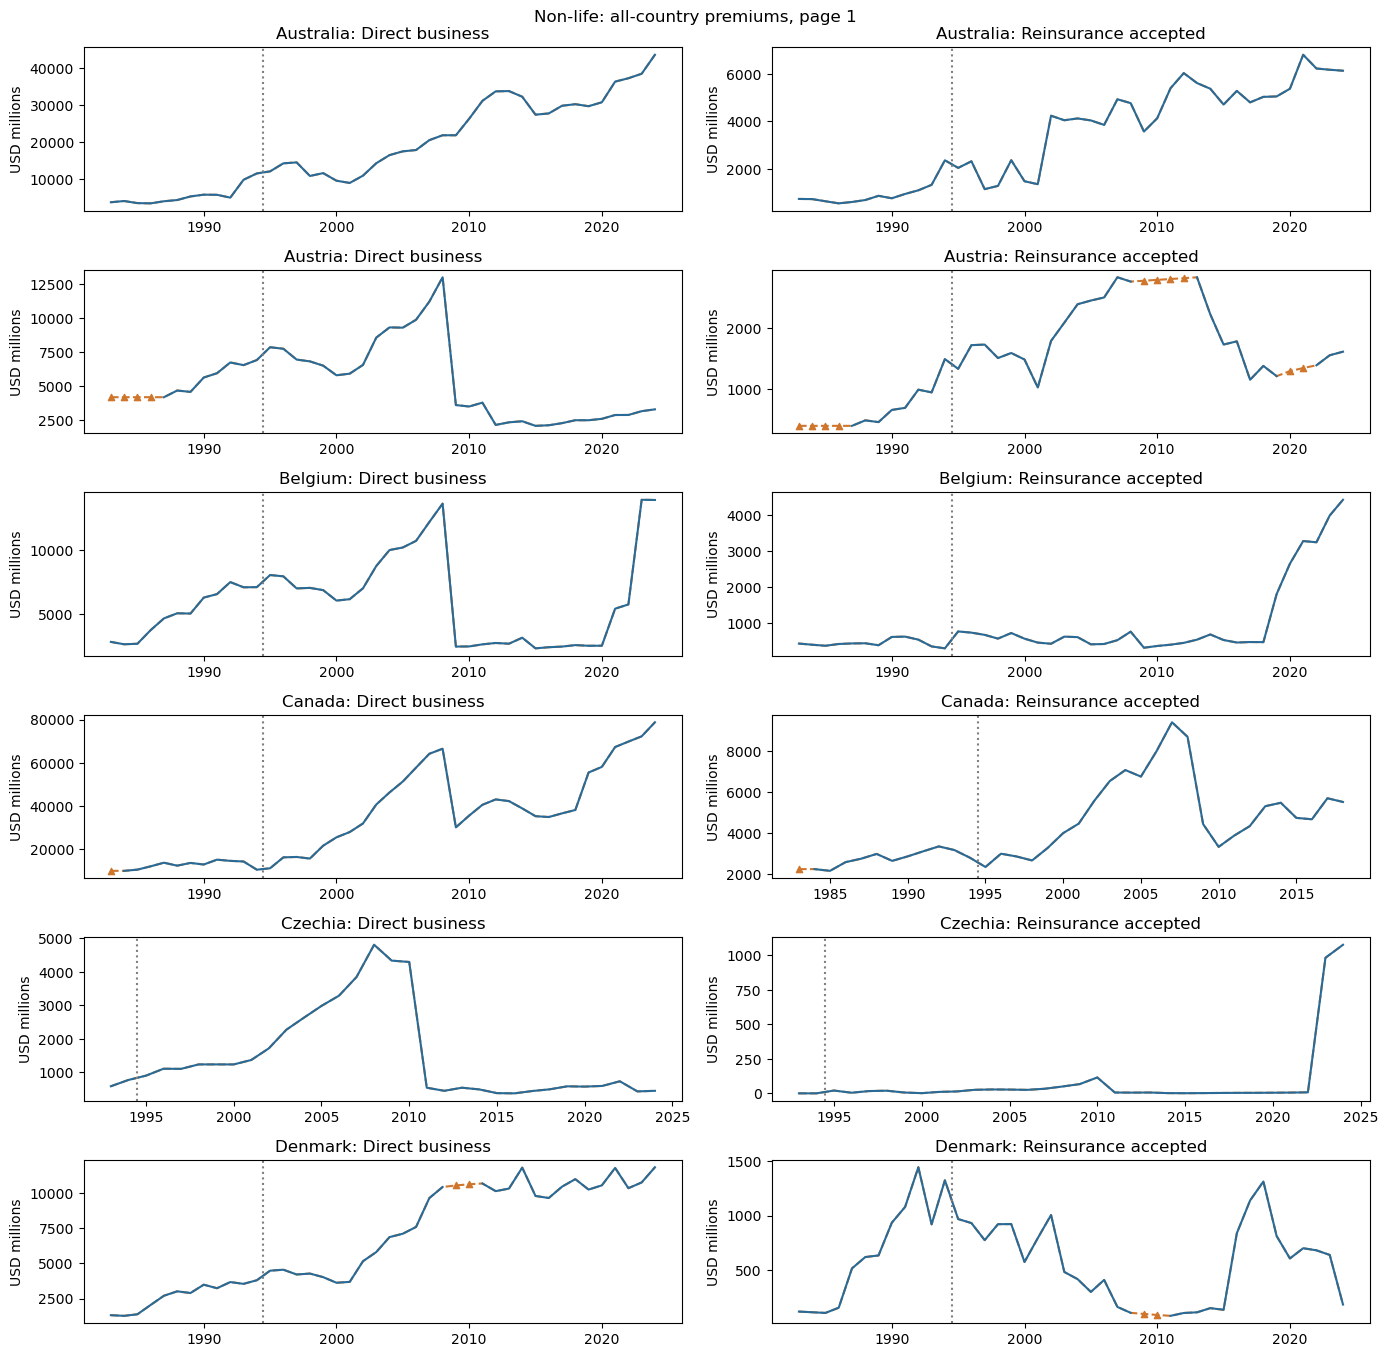

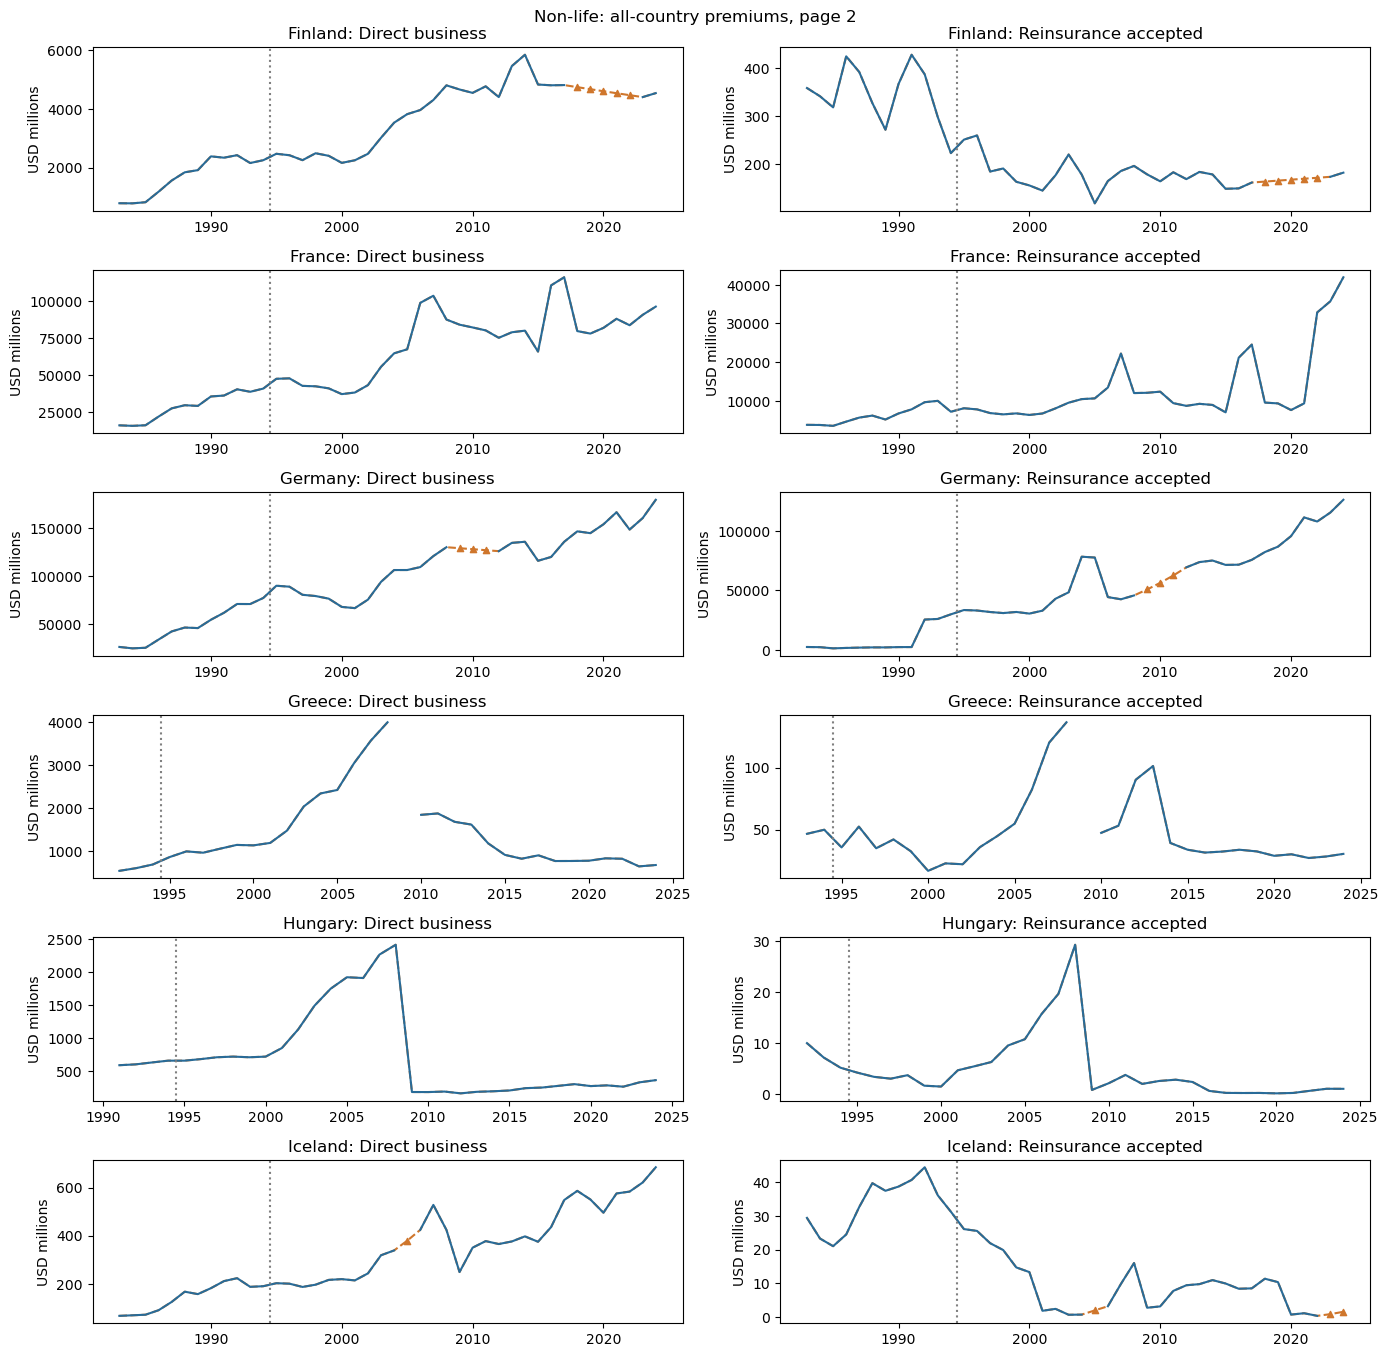

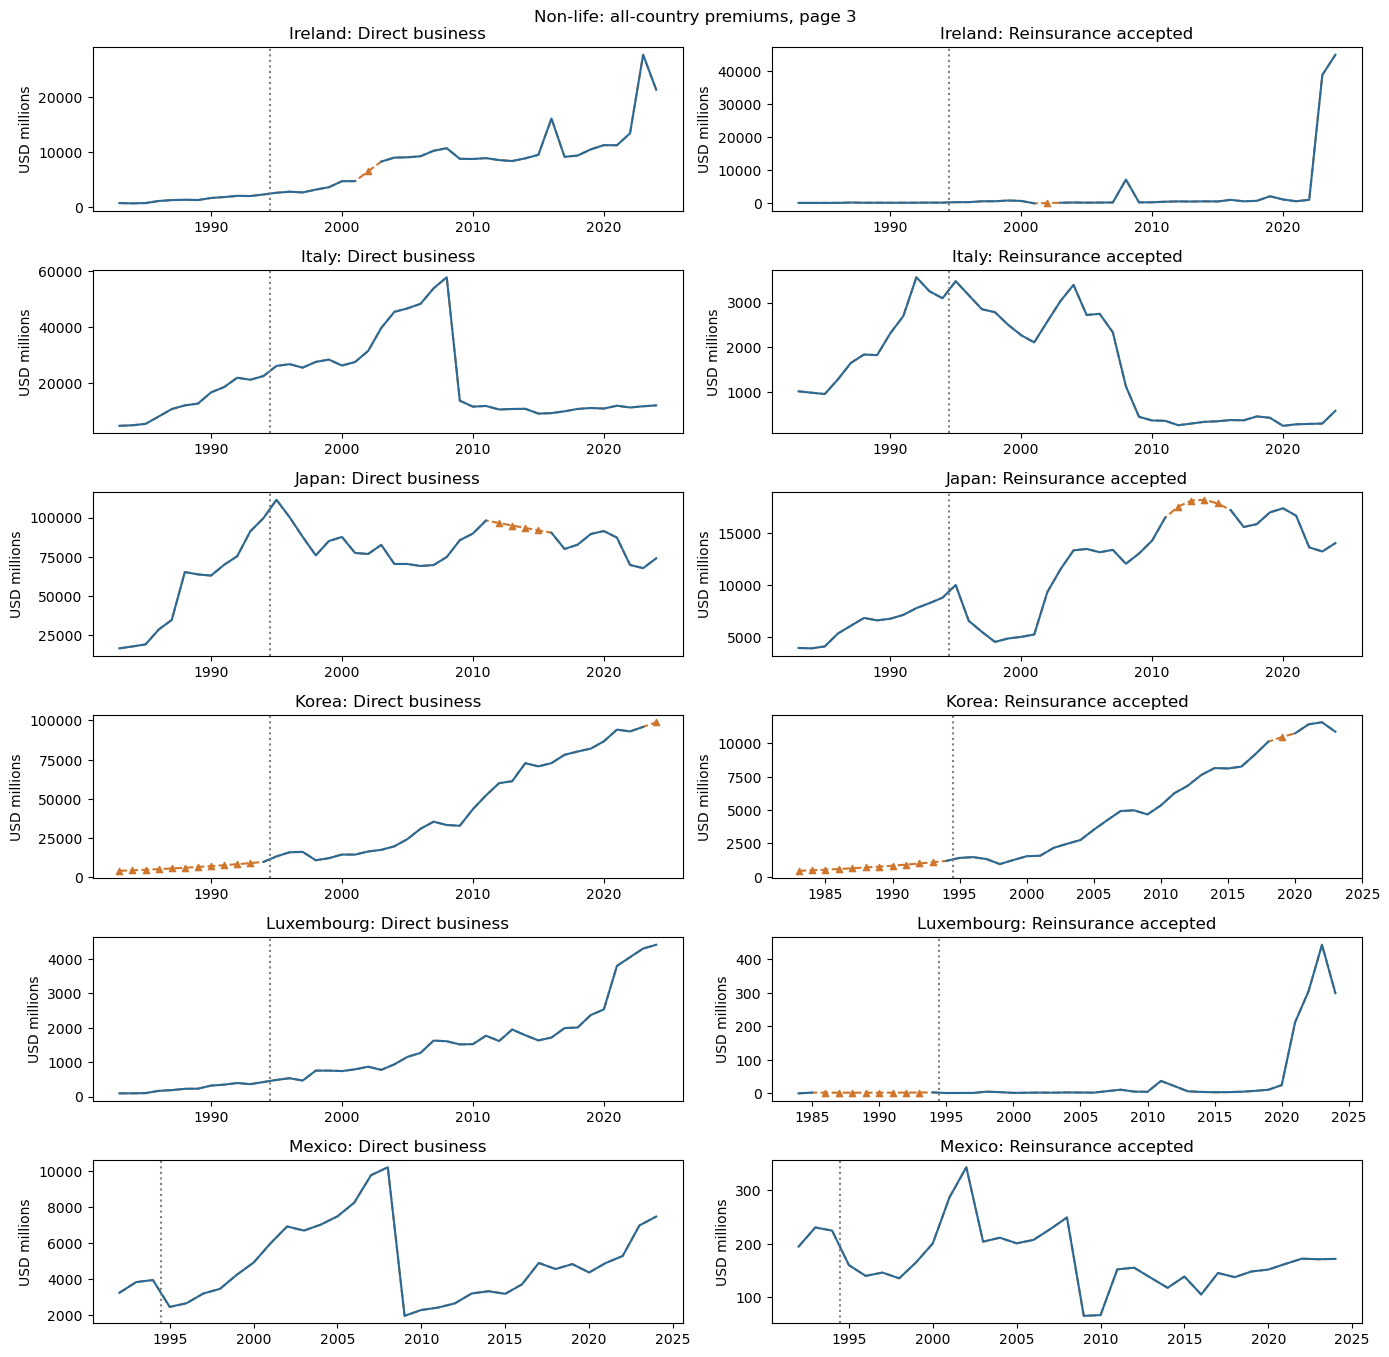

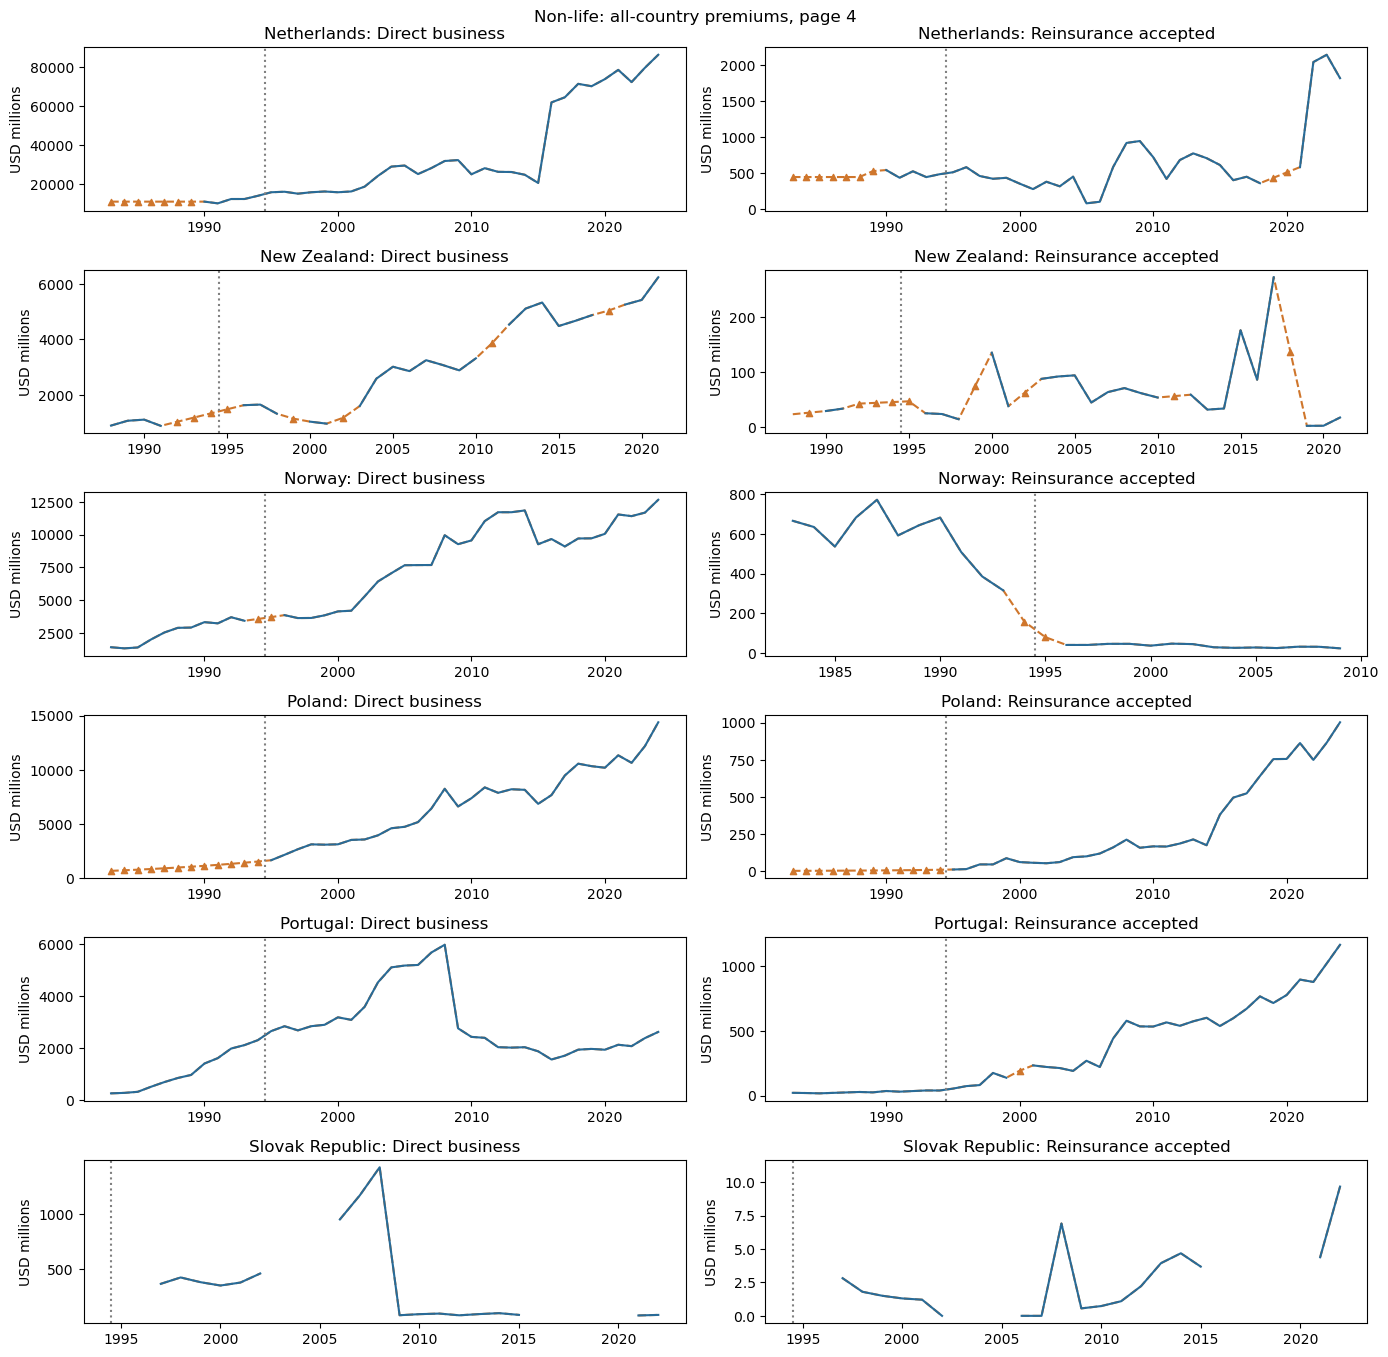

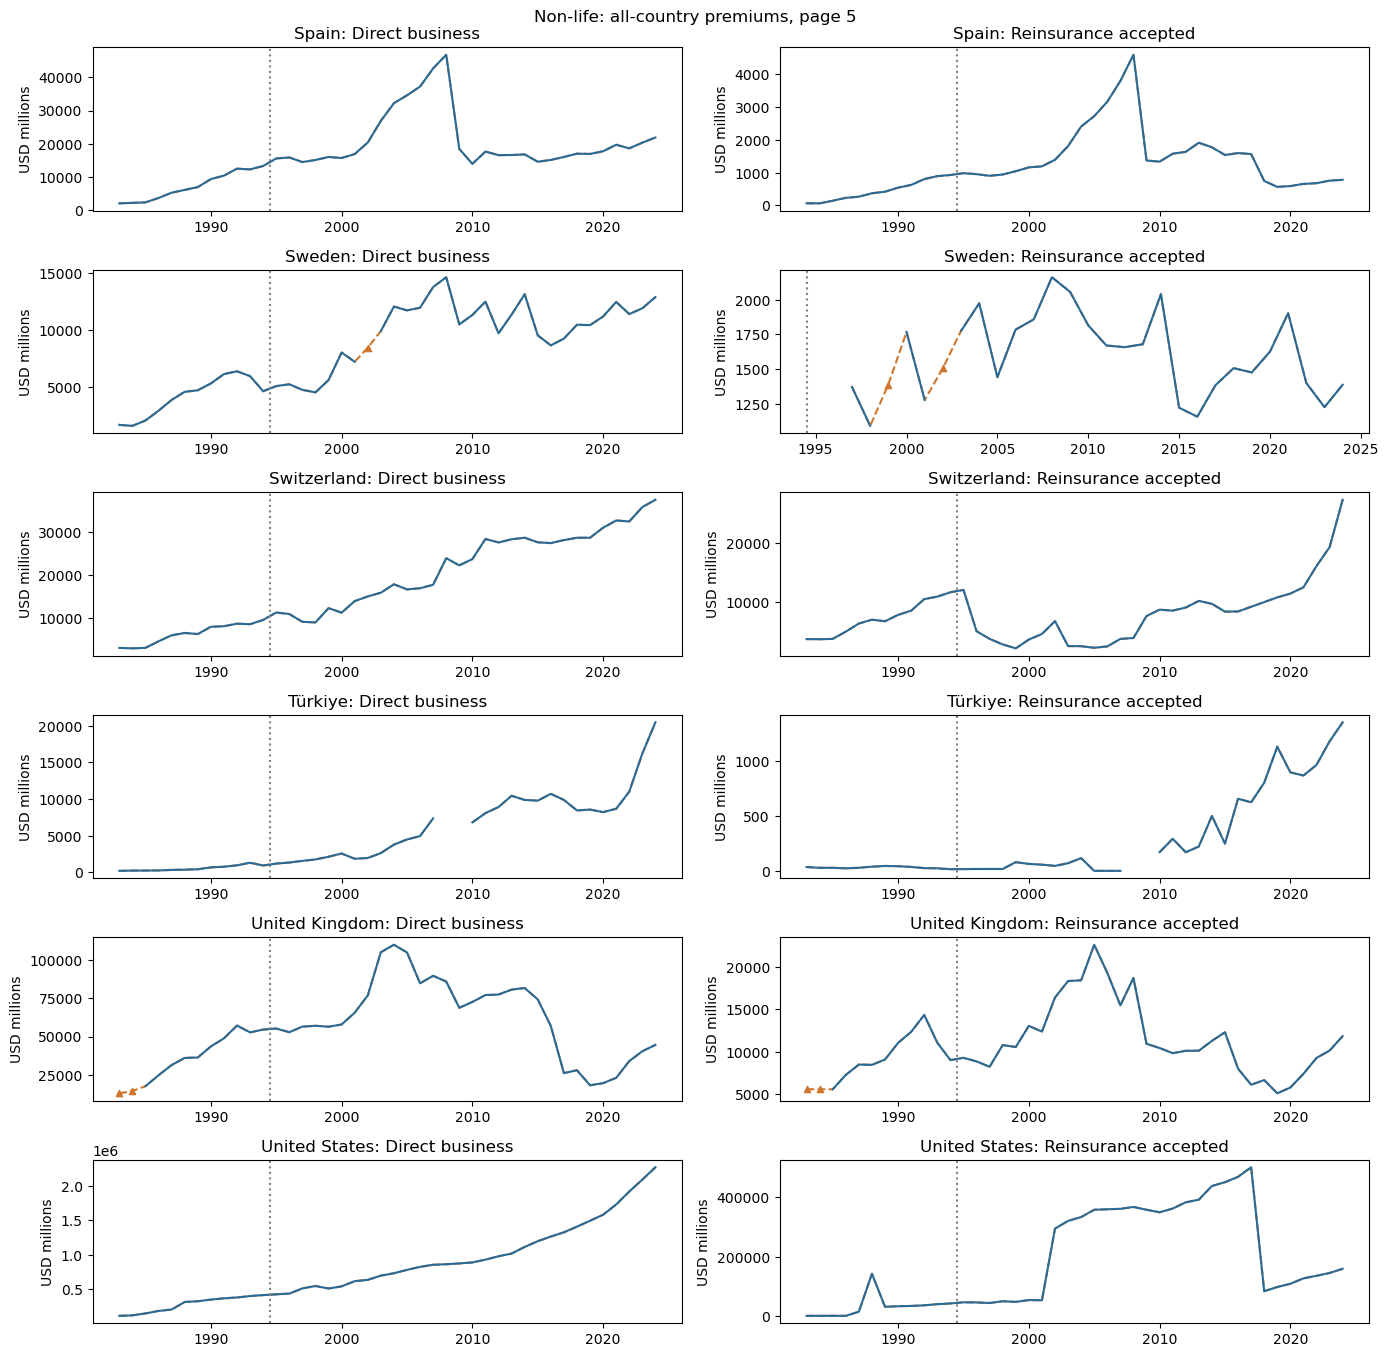

In [ ]:
plot_insurance_type = "Non-life"

if show_all_country_pages:
    for page_start in range(0, len(country_order), countries_per_page):
        page_countries = country_order[page_start:page_start + countries_per_page]
        fig, axes = plt.subplots(len(page_countries), 2, figsize=(14, 2.3 * len(page_countries)), squeeze=False)
        for row_number, country in enumerate(page_countries):
            for column_number, business_type in enumerate(business_types):
                rows = premium_history.loc[
                    premium_history["Country"].eq(country) & premium_history["Type"].eq(plot_insurance_type)
                    & premium_history["Business"].eq(business_type)
                ]
                ax = axes[row_number, column_number]
                ax.plot(rows["Year"], rows["Filled"], "--", color="#cf762c")
                ax.plot(rows["Year"], rows["Observed"], color="#286b98")
                estimated = rows.loc[rows["Is_imputed"]]
                ax.scatter(estimated["Year"], estimated["Filled"], color="#cf762c", marker="^", s=20)
                ax.axvline(1994.5, linestyle=":", color="grey")
                ax.set(title=f"{country}: {business_type}", ylabel="USD millions")
        page_number = page_start // countries_per_page + 1
        fig.suptitle(f"{plot_insurance_type}: all-country premiums, page {page_number}")
        fig.tight_layout()
        plt.show()
        plt.close(fig)

## 16. Count selected methods

Each selected gap is counted once, including pre-1995 gaps. More selections do not mean a method is universally better. 

,Business,Method,Selected_gaps
0,Direct business,arima_level,1
1,Direct business,arima_log,3
2,Direct business,kalman_log,5
3,Direct business,linear_level,3
4,Direct business,linear_log,5
5,Direct business,naive_level,3
6,Reinsurance accepted,arima_log,4
7,Reinsurance accepted,kalman_level,4
8,Reinsurance accepted,kalman_log,2
9,Reinsurance accepted,linear_level,10


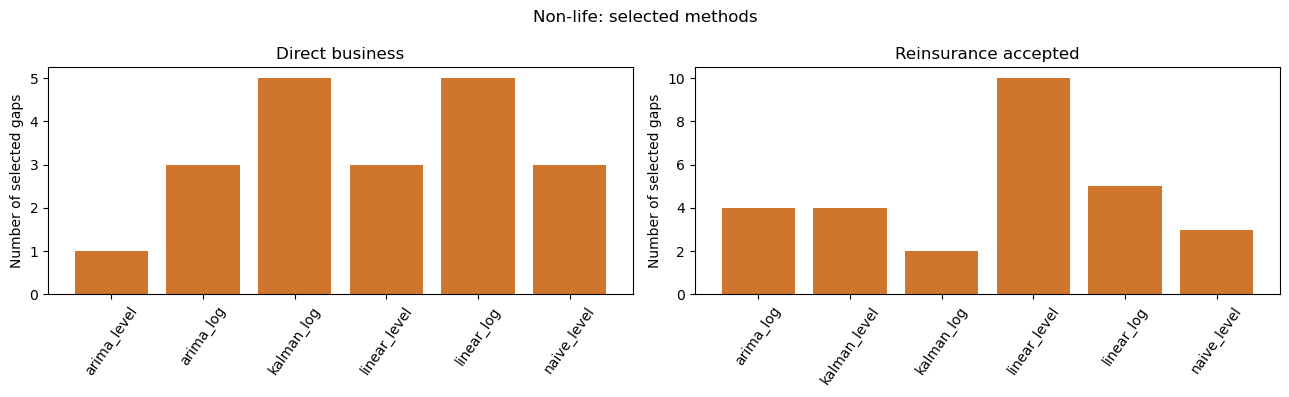

In [44]:
selected_methods = candidate_scores.loc[
    candidate_scores["Type"].eq(plot_insurance_type) & candidate_scores["Selected"]
]
method_counts = selected_methods.groupby(["Business", "Method"]).size().rename("Selected_gaps").reset_index()
display(method_counts)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, business_type in zip(axes, business_types):
    counts = method_counts.loc[method_counts["Business"].eq(business_type)]
    ax.bar(counts["Method"], counts["Selected_gaps"], color="#cf762c")
    ax.tick_params(axis="x", rotation=55)
    ax.set(title=business_type, ylabel="Number of selected gaps")

fig.suptitle(f"{plot_insurance_type}: selected methods")
fig.tight_layout()
plt.show()
plt.close(fig)

## References and reminders

- [Statsmodels local linear trend / Kalman model](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.structural.UnobservedComponents.html)
- [Statsmodels ETS models](https://www.statsmodels.org/stable/examples/notebooks/generated/ets.html)
- [Statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html)

Blocks can overlap. A small validation RMSE does not eliminate imputation uncertainty.
Observed, imputed, derived, and unresolved values remain distinguishable. Python
estimates are not claimed to reproduce the R/PDF numbers exactly.